# MRP baseline for maritime and offshore MRO

An executable explanation of the implementation in `src/`: data preparation, time-phased planning, inventory execution and evaluation. The thesis asks whether DDMRP improves spare-parts availability and inventory performance under uncertain demand and supply lead times. This notebook establishes the traditional forecast-driven baseline against which that question can later be tested.

**Scope:** single-echelon, independent-demand MRO. There is no complete BOM in the supplied data, so the model does not explode dependent requirements. The notebook imports the existing adapter, planner, policy, simulator and KPI functions; only presentation, experiment orchestration and validation are added here.

**Read this distinction throughout:** a proposed MRP plan is not an executed inventory trajectory. An infeasible past-due release is an exception, not an instantaneous receipt.

## Running the notebook

Use Python 3.10+ and a Jupyter-capable editor (for example, the IDE notebook view). From the repository root, install the separate notebook dependencies:

```powershell
python -m pip install -r notebooks/requirements.txt
```

Select that Python environment as the notebook kernel, then **Restart Kernel and Run All**. The default run uses 50 OIL-041 items, executes in memory and leaves existing data/results unchanged. The optional export cell is disabled. The data must already exist under `data/temp_downloads/oil041/` (raw downloads are not tracked in Git).

Sections: setup -> data and preprocessing -> hand calculation -> actual-item plan -> simulation -> results and KPIs -> supply sensitivity -> validation -> limitations and DDMRP comparison.


In [1]:
from pathlib import Path
import sys
import json
import hashlib
import subprocess
import importlib.metadata
from dataclasses import asdict, replace

# Works whether the kernel starts in the project root or notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/mrp/planning.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Start the kernel in the repository root or notebooks directory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.data.adapters import oil041, spdf_oil, records, fingerprints
from src.data.schema import Item
from src.mrp.planning import plan, lot_size, MRPPolicy
from src.simulation.engine import Config, simulate
from src.evaluation.metrics import summarize

get_ipython().run_line_magic('matplotlib', 'inline')
pd.set_option('display.max_columns', 16)
pd.set_option('display.max_rows', 20)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True,
                     'grid.alpha': 0.2, 'axes.spines.top': False, 'axes.spines.right': False})
display(pd.DataFrame({'package': ['Python', 'pandas', 'matplotlib', 'ipykernel'],
    'version': [sys.version.split()[0]] + [importlib.metadata.version(p) for p in ['pandas', 'matplotlib', 'ipykernel']]}))


,package,version
0,Python,3.14.4
1,pandas,3.1.1
2,matplotlib,3.11.2
3,ipykernel,7.4.0


## 1. Experiment configuration

The selection is sorted by part ID, not evaluation-period activity. It is a small reproducible demonstration, not a representative sample. `OFFSHORE_ONLY=True` selects the six offshore facilities identified by the source; it does not create a vessel or warehouse network.

A day is the unit for this OIL-041 experiment. The first 90 days provide forecasting history; inventory execution starts on day 90, with no training-period stock simulation. Cold-start stockouts are included. Default safety stocks come from the undated synthetic snapshot and therefore are **scenario parameters**, not historically validated estimates. Set the override to zero to explore an unbuffered scenario.


In [2]:
MAX_ITEMS = 50
OFFSHORE_ONLY = False
USE_SOURCE_STOCK = False
SAFETY_STOCK_OVERRIDE = None  # None: adapter buffer; otherwise units per SKU
RUN_SENSITIVITY = True
SENSITIVITY_SEEDS = [7, 42, 123]
SOURCE = ROOT / 'data/temp_downloads/oil041'
CONFIG = Config(train_periods=90, forecast_window=60,
                planning_horizon=60, lead_time_cv=0.0, seed=42)
if not (SOURCE / 'maintenance_consumption.csv').is_file():
    raise FileNotFoundError(f'OIL-041 source tables missing at {SOURCE}; see docs/dataset_inventory.md.')
display(pd.DataFrame([{'max_items': MAX_ITEMS, 'offshore_only': OFFSHORE_ONLY,
                       'source_stock': USE_SOURCE_STOCK, **asdict(CONFIG)}]))


,max_items,offshore_only,source_stock,train_periods,forecast_window,planning_horizon,lead_time_cv,seed
0,50,False,False,90,60,60,0.0,42


## 2. Data, provenance and preprocessing

OIL-041 is **synthetic oil-and-gas MRO data**, not observed offshore transactions. The complete public sample contains 13 CSV tables; this adapter uses four. The source's generated emergency/stockout/recommendation labels are not used to decide orders or score the policy. See [dataset inventory](../docs/dataset_inventory.md) and the downloaded [publisher card](../data/temp_downloads/oil041/README.md) for provenance and the CC-BY-NC-4.0 declaration.

| Table used | Role |
|---|---|
| `spare_parts_master.csv` | IDs, USD unit costs and nominal lead times |
| `facility_master.csv` | Optional offshore filtering |
| `maintenance_consumption.csv` | Timestamped consumption, used as a demand proxy |
| `inventory_levels.csv` | Summed safety stock; optional stock net of reservations |

The adapter aggregates consumption by part and day across selected facilities into a virtual pooled stockpoint, fills days without events with zero, rounds nominal lead times upward to at least one day, and preserves original files. Missing stocking pairs do not prove zero physical inventory: their contribution to the constructed scenario is zero. Consumption may be censored by availability and is not necessarily unconstrained demand.


In [3]:
source_files = ['spare_parts_master.csv', 'facility_master.csv',
                'maintenance_consumption.csv', 'inventory_levels.csv']
source_overview = []
for name in source_files:
    rows = records(SOURCE / name)
    source_overview.append({'file': name, 'rows': len(rows), 'columns': len(rows[0]),
                            'blank_cells': sum(v == '' for row in rows for v in row.values())})
display(pd.DataFrame(source_overview))

data = oil041(SOURCE, max_items=MAX_ITEMS, offshore=OFFSHORE_ONLY,
              source_stock=USE_SOURCE_STOCK)
if SAFETY_STOCK_OVERRIDE is not None:
    data.items = {sku: replace(item, safety_stock=SAFETY_STOCK_OVERRIDE)
                  for sku, item in data.items.items()}
data.validate()
items = pd.DataFrame([asdict(i) for i in data.items.values()]).set_index('sku')
demand = pd.DataFrame(data.demand, index=pd.to_datetime(data.periods))
demand.index.name = 'date'
train = demand.iloc[:CONFIG.train_periods]
evaluation = demand.iloc[CONFIG.train_periods:]
# Fix the illustration item using training history only.
EXAMPLE_SKU = train.sum().idxmax()
item = data.items[EXAMPLE_SKU]
display(items.head(8))
display(pd.DataFrame([
    {'split': 'training', 'start': train.index.min(), 'end': train.index.max(), 'periods': len(train), 'units': train.sum().sum()},
    {'split': 'evaluation', 'start': evaluation.index.min(), 'end': evaluation.index.max(), 'periods': len(evaluation), 'units': evaluation.sum().sum()}]))
display(Markdown('**Recorded adapter transformations:**\n\n' + '\n'.join('- ' + t for t in data.metadata['transformations'])))
display(pd.DataFrame([{'source_file': Path(p).name, 'sha256': h} for p, h in data.metadata['sha256'].items()]))


,file,rows,columns,blank_cells
0,spare_parts_master.csv,1500,13,0
1,facility_master.csv,75,6,0
2,maintenance_consumption.csv,25000,11,0
3,inventory_levels.csv,4372,11,0


,unit_cost,lead_time,initial_stock,safety_stock,minimum_order,order_multiple,fixed_order
sku,,,,,,,
PART-000000001,776.24,18,0,4.0,0,1,0
PART-000000002,571.35,63,0,16.0,0,1,0
PART-000000003,85.00,32,0,6.0,0,1,0
PART-000000004,912.87,41,0,8.0,0,1,0
PART-000000005,88.03,32,0,7.0,0,1,0
PART-000000006,177.51,16,0,2.0,0,1,0
PART-000000007,1979.95,52,0,14.0,0,1,0
PART-000000008,3254.15,14,0,2.0,0,1,0


,split,start,end,periods,units
0,training,2021-01-01,2021-03-31,90,519.0
1,evaluation,2021-04-01,2021-12-31,275,1668.0


**Recorded adapter transformations:**

- Parts selected by sorted ID, not future demand.
- Daily consumption summed across selected facilities into one pooled stocking point per part.
- Absent daily consumption treated as zero within the published event horizon.
- Lead times rounded upward to days; minimum one day.
- Safety stock summed across selected inventory rows; missing pairs contribute zero.
- Snapshot safety stock is a synthetic scenario parameter, not a historically known policy.
- No warehouse allocation or transfer network is inferred; no source KPI labels used.

,source_file,sha256
0,spare_parts_master.csv,2b0da65c01ef0c855d087f9d55c735fc9b28f0389ca6a9...
1,facility_master.csv,2f74ff8ed6db68534a07bc38826a39f54c2b3e859b4dbe...
2,maintenance_consumption.csv,cdcb8bd5979655f2f21a29ddcd483883144dcf73c3f2da...
3,inventory_levels.csv,3eb6d88a48ddd3df29f29df503b63da96e0ef33473737b...


,training_units,positive_days,zero_day_share,mean_daily_demand,lead_time,safety_stock
PART-000000005,237.0,27,0.700,2.633,32,7.0
PART-000000024,19.0,8,0.911,0.211,15,7.0
PART-000000011,18.0,9,0.900,0.200,29,8.0
PART-000000007,16.0,7,0.922,0.178,52,14.0
PART-000000018,15.0,8,0.911,0.167,13,1.0
PART-000000003,15.0,8,0.911,0.167,32,6.0
PART-000000033,13.0,5,0.944,0.144,26,7.0
PART-000000040,13.0,9,0.900,0.144,36,1.0


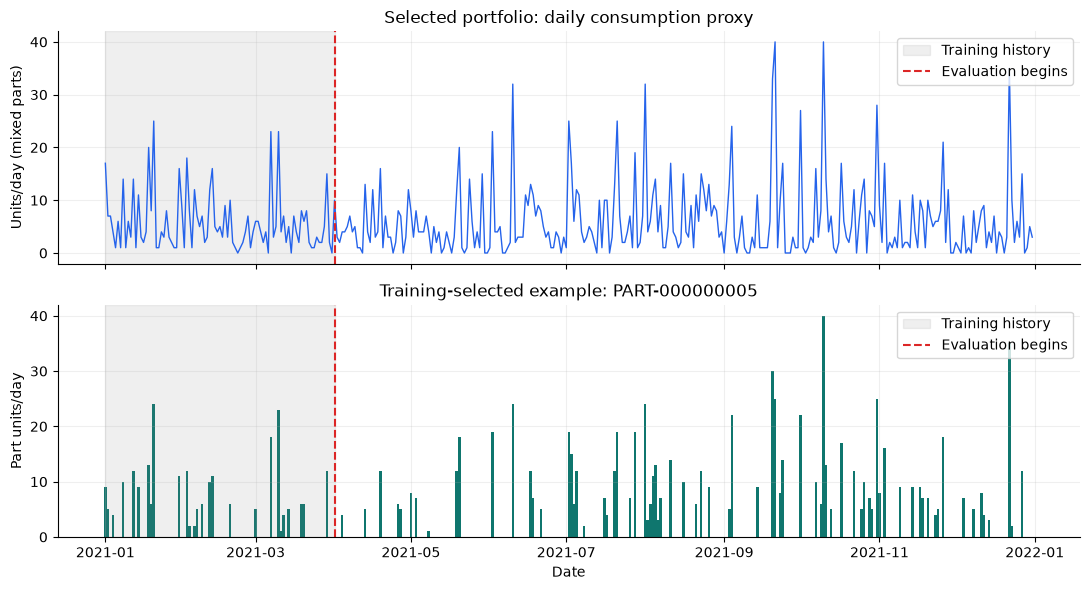

In [4]:
# Describe intermittency on TRAINING data, without tuning to evaluation outcomes.
profile = pd.DataFrame({'training_units': train.sum(),
                        'positive_days': (train > 0).sum(),
                        'zero_day_share': (train == 0).mean(),
                        'mean_daily_demand': train.mean()}).join(items[['lead_time', 'safety_stock']])
display(profile.sort_values('training_units', ascending=False).head(8).round(3))
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(demand.index, demand.sum(axis=1), color='#2563eb', linewidth=1)
axes[0].set(title='Selected portfolio: daily consumption proxy', ylabel='Units/day (mixed parts)')
axes[1].bar(demand.index, demand[EXAMPLE_SKU], color='#0f766e', width=1)
axes[1].set(title=f'Training-selected example: {EXAMPLE_SKU}', ylabel='Part units/day', xlabel='Date')
for ax in axes:
    ax.axvspan(train.index[0], evaluation.index[0], color='gray', alpha=.12, label='Training history')
    ax.axvline(evaluation.index[0], color='#dc2626', linestyle='--', label='Evaluation begins')
    ax.legend(loc='upper right')
fig.tight_layout()
plt.show()


### Alternative empirical candidate: original SPDF oil workbooks

`src.data.adapters.spdf_oil` is available for the thesis's primary empirical candidate. It reads the original workbook halves, reverses chronology, and retains contiguous December 1997-August 2001 observations to avoid the unreliable November 1997. Documented whole-year blanks become zero; unexplained partial-year blanks raise an error. Negative net consumption is rejected unless `returns='clip'` is explicitly chosen as a nonnegative proxy. `Min` is a reorder point, not safety stock; default safety stock is zero. Lead times are converted from days to approximate monthly buckets, and source currency is unspecified.

This is an optional adapter example, **not executed as part of this daily demonstration**:

```python
spdf = spdf_oil(ROOT / 'data/temp_downloads/spdf-main', max_items=50, returns='clip')
spdf_config = Config(train_periods=24, forecast_window=12, planning_horizon=60)
spdf_ledger, spdf_orders, _ = simulate(spdf, MRPPolicy(), spdf_config)
```

Do not compare raw daily/monthly stockout-period counts or combine their monetary totals without harmonizing period definitions and currency.


## 3. MRP calculation process

Let $G_t$ be forecast gross requirements, $SR_t$ committed scheduled receipts, $SS$ safety stock and $PAB_{t-1}$ prior projected available balance. The imported planner calculates:

\[
NR_t = \max(0, G_t + SS - PAB_{t-1} - SR_t)
\]
\[
POR_t = \operatorname{lot\_size}(NR_t),\qquad
PAB_t = PAB_{t-1} + SR_t + POR_t - G_t
\]

A planned receipt in period $t$ requires a release in $t-L$ for nominal lead time $L$. Opening backlog reduces initial availability. Scheduled receipts are already committed supply; planned receipts/releases are proposals. A negative release period is a past-due exception.

Lot-for-lot is rounded upward to the order multiple (default one unit). MOQ applies only for a positive requirement. Optional fixed-lot rounding occurs before packaging-multiple rounding; packaging takes precedence if the two constraints conflict.

**Rolling execution differs:** `MRPPolicy` uses the same planner with `earliest_receipt=L`. Before that fence, no new receipts can be planned and negative projected balances represent deferred shortages. Existing committed receipts are still recognized. Shortfalls are carried to the first feasible receipt and netted against pipeline supply, preventing duplicate orders for an already covered shortage.


### Hand-checkable worked example (illustrative parameters)

Opening stock 12, safety stock 2, lead time 2 periods, order multiple 5; gross requirements `[4, 8, 10, 3]`, with a committed receipt of 5 in period 1. After periods 0 and 1, projected stock is 8 and 5. In period 2, the net requirement is `10 + 2 - 5 = 7`; rounding gives a planned receipt of 10. It must be released in period 0. Projected balances should be `[8, 5, 5, 2]`. These are deliberately transparent teaching inputs, not estimates for a real item.


In [5]:
teaching_item = Item('TEACHING', unit_cost=5, lead_time=2,
                     initial_stock=12, safety_stock=2, order_multiple=5)
teaching_plan = pd.DataFrame([asdict(r) for r in plan(teaching_item, [4, 8, 10, 3], scheduled={1: 5})])
display(teaching_plan)
assert teaching_plan['net_requirements'].tolist() == [0, 0, 7, 0]
assert teaching_plan['planned_receipts'].tolist() == [0, 0, 10, 0]
assert teaching_plan['projected_available'].tolist() == [8, 5, 5, 2]
assert teaching_plan.loc[0, 'planned_releases'] == 10

# Lot sizing uses the production function, not a notebook implementation.
lot_examples = [
    ('L4L integer units', Item('A', 1, 1)),
    ('MOQ 10, package 6', Item('A', 1, 1, minimum_order=10, order_multiple=6)),
    ('Fixed lot 20', Item('A', 1, 1, fixed_order=20)),
]
display(pd.DataFrame([{'rule': label, 'net': net, 'planned_quantity': lot_size(net, rule)}
                      for label, rule in lot_examples for net in [0, 7, 21]]))


,period,gross_requirements,scheduled_receipts,net_requirements,planned_receipts,planned_releases,projected_available,release_period,past_due_release
0,0,4,0,0.0,0.0,10.0,8.0,NaN,False
1,1,8,5,0.0,0.0,0.0,5.0,NaN,False
2,2,10,0,7.0,10.0,0.0,5.0,0.0,False
3,3,3,0,0.0,0.0,0.0,2.0,NaN,False


,rule,net,planned_quantity
0,L4L integer units,0,0.0
1,L4L integer units,7,7.0
2,L4L integer units,21,21.0
3,"MOQ 10, package 6",0,0.0
4,"MOQ 10, package 6",7,12.0
5,"MOQ 10, package 6",21,24.0
6,Fixed lot 20,0,0.0
7,Fixed lot 20,7,20.0
8,Fixed lot 20,21,40.0


In [6]:
# Show why a theoretical past-due plan cannot be used as physical inventory.
fence_item = Item('FENCE', unit_cost=1, lead_time=2)
comparison = pd.concat([
    pd.DataFrame([asdict(r) for r in plan(fence_item, [4, 4, 4])]).assign(plan_type='Unconstrained'),
    pd.DataFrame([asdict(r) for r in plan(fence_item, [4, 4, 4], earliest_receipt=2)]).assign(plan_type='Feasible receipts'),
], ignore_index=True)
display(comparison[['plan_type', 'period', 'gross_requirements', 'net_requirements',
                    'planned_receipts', 'release_period', 'past_due_release', 'projected_available']])
assert comparison.loc[comparison.plan_type == 'Feasible receipts', 'planned_receipts'].tolist() == [0, 0, 12]


,plan_type,period,gross_requirements,net_requirements,planned_receipts,release_period,past_due_release,projected_available
0,Unconstrained,0,4,4.0,4.0,-2.0,True,0.0
1,Unconstrained,1,4,4.0,4.0,-1.0,True,0.0
2,Unconstrained,2,4,4.0,4.0,0.0,False,0.0
3,Feasible receipts,0,4,4.0,0.0,NaN,False,-4.0
4,Feasible receipts,1,4,8.0,0.0,NaN,False,-8.0
5,Feasible receipts,2,4,12.0,12.0,0.0,False,0.0


### Actual selected item: first evaluation decision

Below, gross requirements are the constant trailing training mean, not future actual consumption. The planner extends the horizon to at least lead time + 1. Period 0 is the first evaluation day; it is a **relative** period, unlike the full-calendar indices in the simulation ledger. The safety-stock and unit-cost inputs are displayed explicitly.


,sku,unit_cost,lead_time,initial_stock,safety_stock,minimum_order,order_multiple,fixed_order,forecast_units_per_day,release_now_units
0,PART-000000005,88.03,32,0,7.0,0,1,0,2.233333,81.0


,period,gross_requirements,scheduled_receipts,net_requirements,planned_receipts,planned_releases,projected_available,release_period,past_due_release
0,0,2.233,0,9.233,0.0,81.0,-2.233,NaN,False
1,1,2.233,0,11.467,0.0,2.0,-4.467,NaN,False
2,2,2.233,0,13.700,0.0,3.0,-6.700,NaN,False
3,3,2.233,0,15.933,0.0,2.0,-8.933,NaN,False
30,30,2.233,0,76.233,0.0,0.0,-69.233,NaN,False
31,31,2.233,0,78.467,0.0,0.0,-71.467,NaN,False
32,32,2.233,0,80.700,81.0,0.0,7.300,0.0,False
33,33,2.233,0,1.933,2.0,0.0,7.067,1.0,False
34,34,2.233,0,2.167,3.0,0.0,7.833,2.0,False


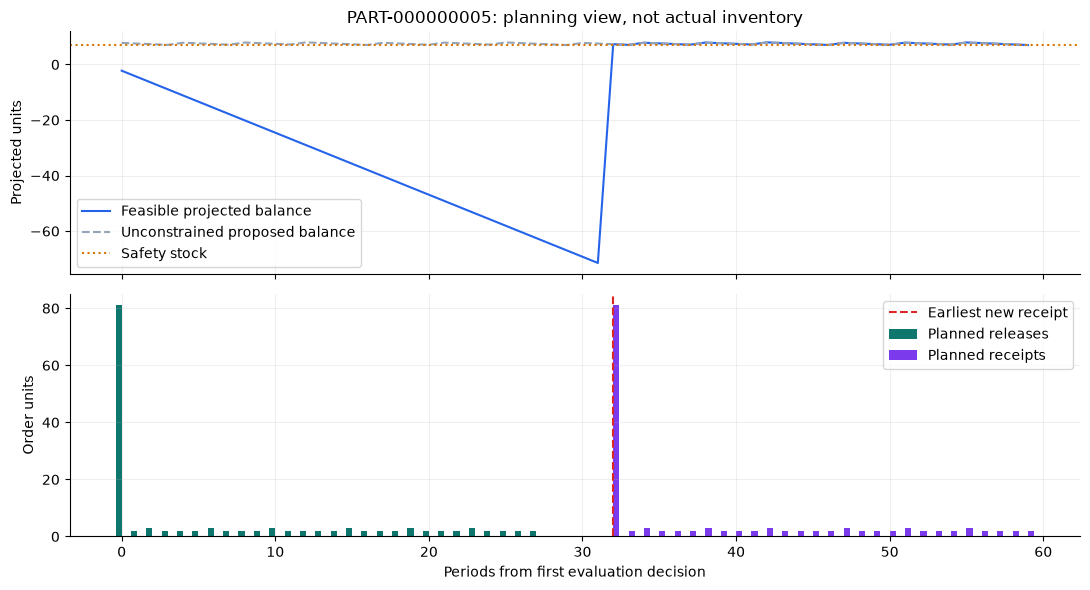

In [7]:
history = data.demand[EXAMPLE_SKU][:CONFIG.train_periods]
forecast = sum(history[-CONFIG.forecast_window:]) / len(history[-CONFIG.forecast_window:])
horizon = max(CONFIG.planning_horizon, item.lead_time + 1)
gross = [forecast] * horizon
unconstrained = pd.DataFrame([asdict(r) for r in plan(item, gross)])
release_now, audit = MRPPolicy().decide(item, history, item.initial_stock, 0, {}, horizon, CONFIG.forecast_window)
feasible = pd.DataFrame(audit)
display(pd.DataFrame([{**asdict(item), 'forecast_units_per_day': forecast, 'release_now_units': release_now}]))
# Show early periods and the receipt-fence neighborhood without printing the whole horizon.
show_periods = sorted(set(range(min(4, horizon))) | set(range(max(0, item.lead_time - 2), min(horizon, item.lead_time + 3))))
display(feasible.iloc[show_periods].round(3))
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(feasible.period, feasible.projected_available, label='Feasible projected balance', color='#2563eb')
axes[0].plot(unconstrained.period, unconstrained.projected_available, '--', label='Unconstrained proposed balance', color='#94a3b8')
axes[0].axhline(item.safety_stock, color='#d97706', linestyle=':', label='Safety stock')
axes[0].set(ylabel='Projected units', title=f'{EXAMPLE_SKU}: planning view, not actual inventory')
axes[0].legend()
axes[1].bar(feasible.period - .2, feasible.planned_releases, width=.4, label='Planned releases', color='#0f766e')
axes[1].bar(feasible.period + .2, feasible.planned_receipts, width=.4, label='Planned receipts', color='#7c3aed')
axes[1].axvline(item.lead_time, color='#dc2626', linestyle='--', label='Earliest new receipt')
axes[1].set(xlabel='Periods from first evaluation decision', ylabel='Order units')
axes[1].legend()
fig.tight_layout()
plt.show()


## 4. Execute the existing simulation

Each period: **receive -> fulfil old backlog -> forecast/replan/release -> observe current demand -> fulfil/backorder -> update history**. The decision cannot see current demand or realized future lead-time shocks. Forecasting uses a rolling mean of observed past consumption. New orders cannot arrive instantly; future proposals are replanned rather than automatically committed.

Outstanding orders are shown to the policy at nominal due dates. If late, their expected receipt is pushed to the next period until they arrive. This is a modelling assumption, not supplier confirmation. Backorders are served before new demand. There is no emergency/expedite policy, loss-of-sales logic or inventory disposal.


In [8]:
ledger_rows, order_rows, decision_rows = simulate(data, MRPPolicy(), CONFIG)
metrics = summarize(ledger_rows, order_rows)
ledger = pd.DataFrame(ledger_rows)
ledger['date'] = pd.to_datetime(ledger['date'])
orders = pd.DataFrame(order_rows, columns=['order_id', 'sku', 'release_period', 'nominal_due',
    'actual_due', 'quantity', 'actual_lead_time', 'emergency', 'received_within_horizon'])
decisions = pd.DataFrame(decision_rows)
display(ledger.head(6).round(3))
display(orders.head(6))
print(f'Executed {metrics["items"]} items over {metrics["evaluation_periods"]} evaluation periods.')


C:\Users\danie\AppData\Local\Temp\ipykernel_17464\3945164666.py:8: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(ledger.head(6).round(3))


,sku,period,date,opening_stock,receipts,opening_backlog,backlog_fulfilled,demand,immediate_fulfilled,unmet_demand,closing_stock,closing_backlog,inventory_value,pipeline_qty,released_qty
0,PART-000000001,90,2021-04-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,5.0
1,PART-000000001,91,2021-04-02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,0.0
2,PART-000000001,92,2021-04-03,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,0.0
3,PART-000000001,93,2021-04-04,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,0.0
4,PART-000000001,94,2021-04-05,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,0.0
5,PART-000000001,95,2021-04-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,0.0


,order_id,sku,release_period,nominal_due,actual_due,quantity,actual_lead_time,emergency,received_within_horizon
0,PART-000000001:90,PART-000000001,90,108,108,5.0,18,False,True
1,PART-000000001:208,PART-000000001,208,226,226,1.0,18,False,True
2,PART-000000001:256,PART-000000001,256,274,274,1.0,18,False,True
3,PART-000000002:90,PART-000000002,90,153,153,27.0,63,False,True
4,PART-000000002:127,PART-000000002,127,190,190,1.0,63,False,True
5,PART-000000002:128,PART-000000002,128,191,191,2.0,63,False,True


Executed 50 items over 275 evaluation periods.


## 5. Results and KPI definitions

| KPI | Interpretation |
|---|---|
| Unit fill rate | Units fulfilled immediately / requested units; later backlog service does not repair this rate |
| Demand-period service rate | Fraction of positive-demand item-periods fully served; **not cycle service level** |
| Stockout item-periods | Item-periods with unmet new demand, not distinct episodes |
| Backlog item-periods / ending backlog | Duration proxy and unresolved shortages at the horizon |
| Average inventory value | Mean over periods of aggregate end-period on-hand x USD unit cost; excludes pipeline |
| Ending pipeline | Ordered units arriving beyond the evaluation boundary; not artificially received at the end |
| Regular / emergency orders | Committed orders; emergency count is zero by construction, not estimated operational performance |

Zero-demand service rates are undefined (`None`), not 100%. Mixed-part unit totals have limited economic meaning. No holding-cost rate, emergency freight price or downtime cost is invented; inventory value is not total supply-chain cost. Early stockouts include cold-start effects.


,KPI,value,unit
0,total_demand,1668.0000,units
1,unit_fill_rate,0.5857,fraction
2,demand_period_service_rate,0.6922,fraction
3,stockout_item_periods,169.0000,item-days
4,backlog_item_periods,1454.0000,item-days
5,unmet_units_at_request,691.0000,units
6,ending_backlog,1.0000,units
7,average_inventory_units,352.1927,units
8,average_inventory_value,337787.8359,USD
9,ending_pipeline_units,105.0000,units


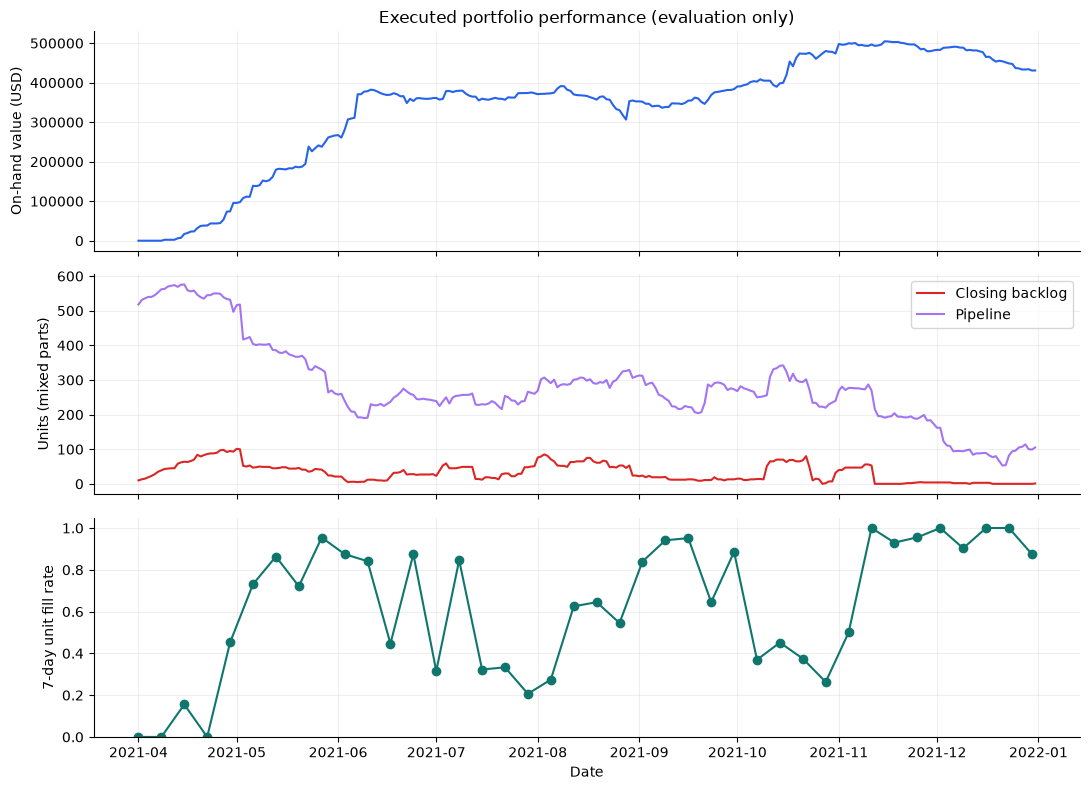

In [9]:
units = {
    'unit_fill_rate': 'fraction', 'demand_period_service_rate': 'fraction',
    'average_inventory_value': data.metadata['currency'],
    'stockout_item_periods': 'item-days', 'backlog_item_periods': 'item-days',
    'regular_orders': 'orders', 'emergency_orders': 'orders',
    'evaluation_periods': 'days', 'items': 'SKUs',
}
display(pd.DataFrame([{'KPI': k, 'value': v, 'unit': units.get(k, 'units')}
                      for k, v in metrics.items()]).round(4))
portfolio = ledger.groupby('date')[['demand', 'immediate_fulfilled', 'unmet_demand',
    'closing_stock', 'closing_backlog', 'inventory_value', 'pipeline_qty']].sum()
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axes[0].plot(portfolio.index, portfolio.inventory_value, color='#2563eb')
axes[0].set(title='Executed portfolio performance (evaluation only)', ylabel='On-hand value (USD)')
axes[1].plot(portfolio.index, portfolio.closing_backlog, color='#dc2626', label='Closing backlog')
axes[1].plot(portfolio.index, portfolio.pipeline_qty, color='#7c3aed', alpha=.7, label='Pipeline')
axes[1].set(ylabel='Units (mixed parts)'); axes[1].legend()
weekly = portfolio[['demand', 'immediate_fulfilled']].resample('7D').sum()
weekly_fill = weekly.immediate_fulfilled.div(weekly.demand.where(weekly.demand > 0))
axes[2].plot(weekly.index, weekly_fill, marker='o', color='#0f766e')
axes[2].set(ylabel='7-day unit fill rate', xlabel='Date', ylim=(0, 1.05))
fig.tight_layout()
plt.show()


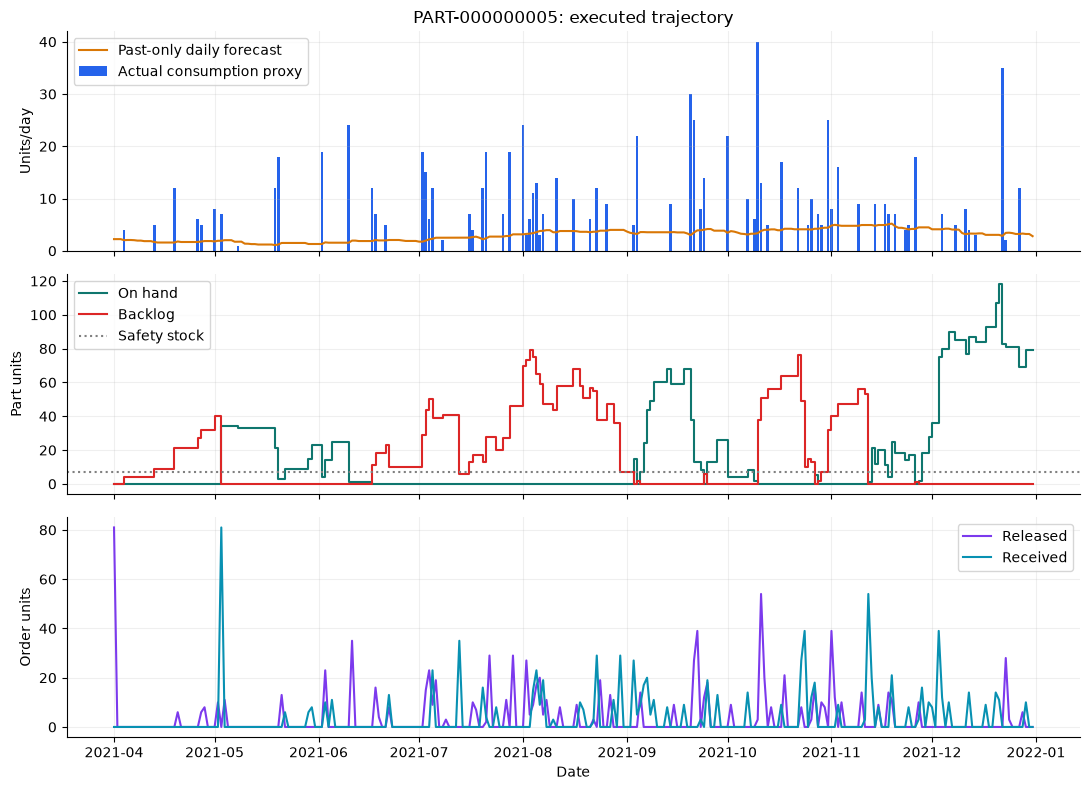

,demand,receipts,immediate_fulfilled,unmet_demand,closing_backlog
date,,,,,
2021-04-04,4.0,0.0,0.0,4.0,4.0
2021-04-13,5.0,0.0,0.0,5.0,9.0
2021-04-19,12.0,0.0,0.0,12.0,21.0
2021-04-26,6.0,0.0,0.0,6.0,27.0
2021-04-27,5.0,0.0,0.0,5.0,32.0
2021-05-01,8.0,0.0,0.0,8.0,40.0
2021-06-17,12.0,0.0,1.0,11.0,11.0
2021-06-18,7.0,0.0,0.0,7.0,18.0


In [10]:
item_ledger = ledger.loc[ledger.sku == EXAMPLE_SKU].set_index('date')
item_decisions = decisions.loc[decisions.sku == EXAMPLE_SKU].copy()
item_decisions['date'] = pd.to_datetime(item_decisions['date'])
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axes[0].bar(item_ledger.index, item_ledger.demand, label='Actual consumption proxy', color='#2563eb')
axes[0].plot(item_decisions.date, item_decisions.forecast_per_period, label='Past-only daily forecast', color='#d97706')
axes[0].set(title=f'{EXAMPLE_SKU}: executed trajectory', ylabel='Units/day'); axes[0].legend()
axes[1].step(item_ledger.index, item_ledger.closing_stock, where='post', label='On hand', color='#0f766e')
axes[1].step(item_ledger.index, item_ledger.closing_backlog, where='post', label='Backlog', color='#dc2626')
axes[1].axhline(item.safety_stock, color='gray', linestyle=':', label='Safety stock')
axes[1].set(ylabel='Part units'); axes[1].legend()
axes[2].plot(item_ledger.index, item_ledger.released_qty, label='Released', color='#7c3aed')
axes[2].plot(item_ledger.index, item_ledger.receipts, label='Received', color='#0891b2')
axes[2].set(ylabel='Order units', xlabel='Date'); axes[2].legend()
fig.tight_layout()
plt.show()
# Inspection selection only: never fed back into the policy.
stockouts = item_ledger[item_ledger.unmet_demand > 0]
display(stockouts.head(8)[['demand', 'receipts', 'immediate_fulfilled', 'unmet_demand', 'closing_backlog']])


The item trace links releases to delayed receipts and shows whether a stockout comes with an existing pipeline. A nonzero buffer does not guarantee immediate service under intermittent consumption and long lead times. Aggregate fill rates can hide item-level failures; inspect individual items and criticality groups before drawing conclusions. The displayed item was selected using training activity only. These demonstration outcomes are not a tuned optimum or a DDMRP comparison.

## 6. Controlled supply-uncertainty illustration

Keep the same items, demand, initialization, buffer, forecast window and KPI definitions. Change only lead-time CV/seed. The simulator uses a mean-one lognormal lead-time multiplier, then ceilings to a whole day with minimum one. Thus realized means/CVs need not equal nominal settings. These shocks are assumed, not fitted to OIL-041 supplier records.

Random shocks are keyed by seed, SKU and release period: policies releasing the same item on the same date share a shock, but different release schedules need not encounter the same realized delays. The three seeds below are an exploratory variability check, **not confidence intervals or a sufficient robustness experiment**. Demand is held fixed; later thesis experiments must vary demand regimes separately.


,scenario,unit_fill_rate,average_inventory_value,stockout_item_periods,ending_backlog,ending_pipeline_units
0,Deterministic,0.5857,337787.8359,169,1.0,105.0
1,CV 0.5 / seed 7,0.6667,358445.2522,146,1.0,126.0
2,CV 0.5 / seed 42,0.6553,329908.5008,154,1.0,107.0
3,CV 0.5 / seed 123,0.6541,341972.7382,157,1.0,124.0


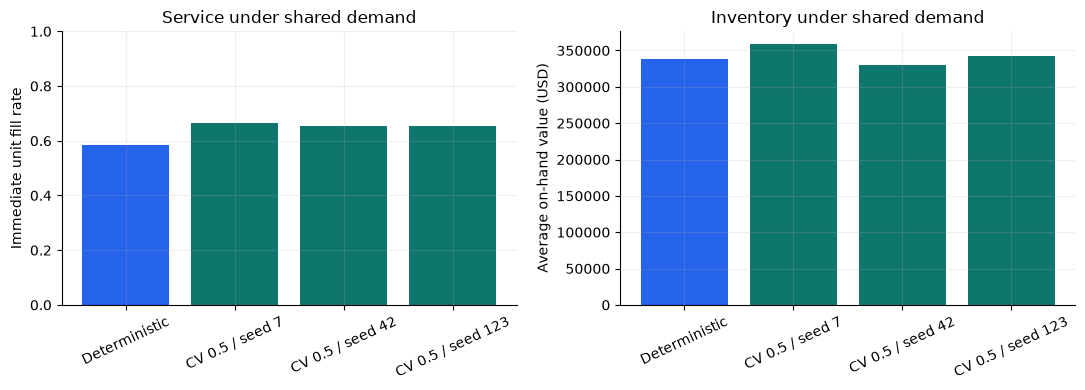

In [11]:
scenario_results = [{'scenario': 'Deterministic', 'cv': 0.0, 'seed': CONFIG.seed, **metrics}]
if RUN_SENSITIVITY:
    for seed in SENSITIVITY_SEEDS:
        scenario_config = replace(CONFIG, lead_time_cv=0.5, seed=seed)
        rows, scenario_orders, _ = simulate(data, MRPPolicy(), scenario_config)
        scenario_results.append({'scenario': f'CV 0.5 / seed {seed}', 'cv': .5, 'seed': seed,
                                 **summarize(rows, scenario_orders)})
scenario_table = pd.DataFrame(scenario_results)
display(scenario_table[['scenario', 'unit_fill_rate', 'average_inventory_value',
                        'stockout_item_periods', 'ending_backlog', 'ending_pipeline_units']].round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
colors = ['#2563eb'] + ['#0f766e'] * (len(scenario_table) - 1)
axes[0].bar(scenario_table.scenario, scenario_table.unit_fill_rate, color=colors)
axes[0].set(ylabel='Immediate unit fill rate', ylim=(0, 1), title='Service under shared demand')
axes[1].bar(scenario_table.scenario, scenario_table.average_inventory_value, color=colors)
axes[1].set(ylabel='Average on-hand value (USD)', title='Inventory under shared demand')
for ax in axes:
    ax.tick_params(axis='x', rotation=25)
fig.tight_layout()
plt.show()


More variable lead times can include earlier as well as later arrivals, so service need not deteriorate monotonically in this experiment. Different arrival patterns also change subsequent ordering. These few outcomes do not establish that greater variability improves performance.

## 7. Validation and reproducibility

These checks validate implementation, not empirical realism. They verify stock/backlog/pipeline conservation, nonnegative physical states, regular lead-time delays, the hand calculation and original-source preservation. The existing test suite additionally checks that changing future demand cannot change earlier decisions, that incoming supply prevents duplicate shortage orders, and that uncertain lead times are reproducible. Run hashes below identify the implementation used by this notebook.


In [12]:
checks = {}
stock_residual = (ledger.opening_stock + ledger.receipts - ledger.backlog_fulfilled
                  - ledger.immediate_fulfilled - ledger.closing_stock)
backlog_residual = (ledger.opening_backlog - ledger.backlog_fulfilled
                    + ledger.unmet_demand - ledger.closing_backlog)
checks['stock balance, every item-period'] = stock_residual.abs().max() < 1e-8
checks['backlog balance, every item-period'] = backlog_residual.abs().max() < 1e-8
checks['nonnegative physical stock/backlog'] = bool((ledger[['closing_stock', 'closing_backlog']] >= 0).all().all())
terminal = ledger.groupby('sku').tail(1)
checks['pipeline conservation'] = abs(sum(o['quantity'] for o in order_rows)
    - ledger.receipts.sum() - terminal.pipeline_qty.sum()) < 1e-8
checks['no instantaneous new order receipts'] = all(o['actual_due'] > o['release_period'] for o in order_rows)
checks['source files unchanged'] = all(hashlib.sha256(Path(p).read_bytes()).hexdigest() == h
                                     for p, h in data.metadata['sha256'].items())
display(pd.DataFrame([{'check': k, 'passed': bool(v)} for k, v in checks.items()]))
assert all(checks.values()), 'An inventory or provenance check failed.'
implementation_hashes = fingerprints(sorted((ROOT / 'src').rglob('*.py')))
display(pd.DataFrame([{'module': str(Path(p).relative_to(ROOT)), 'sha256': h}
                      for p, h in implementation_hashes.items()]))


,check,passed
0,"stock balance, every item-period",True
1,"backlog balance, every item-period",True
2,nonnegative physical stock/backlog,True
3,pipeline conservation,True
4,no instantaneous new order receipts,True
5,source files unchanged,True


,module,sha256
0,src\__init__.py,df06ae96e4ed1cca55e26f9f8803a4e4f79eebd307ba9a...
1,src\data\__init__.py,5a0cf2b4e717a6013442cc537e3a418bbf2f1cdff4720b...
2,src\data\adapters.py,d3ab1d44f8edc1295b4e671bee95b2a005314ba3d60f27...
3,src\data\schema.py,d8bb6a6373769e97aedd4a09842285e0a08518d8450c5e...
4,src\evaluation\__init__.py,9ddb6abe105d579a900fdf4b22754b95bc3b0019cc3c4b...
5,src\evaluation\metrics.py,d4cf12eb5e5cdd48f9e2664c3befb5b0c1ca1de74a54cb...
6,src\mrp\__init__.py,4f4d1e5192ed67584b030ea07897efc90d0eac20c72a2d...
7,src\mrp\__main__.py,6b2f4ff5398736ed530ed82b032cb09f258dfc2b2158b7...
8,src\mrp\planning.py,69bd7f757852f0467f27b16672c1b6d798940b67821d80...
9,src\simulation\__init__.py,234df647325374dc034ac944b3c3d1d7388a70cb3fd62a...


In [13]:
# Use the repository tests, not copies embedded in this notebook.
completed = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-v'],
                           cwd=ROOT, capture_output=True, text=True)
print(completed.stderr)
if completed.returncode:
    print(completed.stdout)
    raise RuntimeError('Repository tests failed.')


test_daily_aggregation_and_offshore_filter (test_mrp.AdapterAndCLITests.test_daily_aggregation_and_offshore_filter) ... ok
test_end_to_end_and_no_source_changes (test_mrp.AdapterAndCLITests.test_end_to_end_and_no_source_changes) ... ok
test_spdf_chronology_returns_and_unknown_blanks (test_mrp.AdapterAndCLITests.test_spdf_chronology_returns_and_unknown_blanks) ... ok
test_backlog_and_safety_stock (test_mrp.PlanningTests.test_backlog_and_safety_stock) ... ok
test_feasible_receipt_carries_shortfall (test_mrp.PlanningTests.test_feasible_receipt_carries_shortfall) ... ok
test_hand_calculated_netting_and_offset (test_mrp.PlanningTests.test_hand_calculated_netting_and_offset) ... ok
test_lot_sizes (test_mrp.PlanningTests.test_lot_sizes) ... ok
test_outstanding_supply_prevents_duplicate_shortage_orders (test_mrp.PlanningTests.test_outstanding_supply_prevents_duplicate_shortage_orders) ... ok
test_past_due_explicit (test_mrp.PlanningTests.test_past_due_explicit) ... ok
test_validation (test_mrp

## 8. Outputs and optional export

All analysis above is generated in memory from `src/`. It does not load stale files from `results/my_mrp_run/` or overwrite them. The CLI's outputs are:

| File | Contents |
|---|---|
| `items.csv`, `demand.csv` | Canonical inputs and chronological split |
| `initial_plan.csv` | Unconstrained initial proposal with past-due flags; not the executed trajectory |
| `decisions.csv` | Rolling forecasts and committed release decisions |
| `orders.csv` | Nominal/actual receipt periods and horizon-censoring flag |
| `inventory.csv` | Physical stock, receipts, immediate fulfilment and backlog |
| `metrics.json`, `run.json` | Common KPIs, configuration, assumptions and source/code hashes |

Enable the cell below only to save a **new** baseline run. It calls the existing CLI orchestrator, preserving its serialization and provenance logic. The comparison scenarios remain in this notebook. The CLI refuses to overwrite an existing run directory.


In [14]:
EXPORT_BASELINE = False
if EXPORT_BASELINE:
    from datetime import datetime, timezone
    from src.mrp.__main__ import main as run_cli
    output = ROOT / 'results' / ('mrp_notebook_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
    arguments = ['--input', str(SOURCE), '--output', str(output), '--max-items', str(MAX_ITEMS),
                 '--train-periods', str(CONFIG.train_periods), '--forecast-window', str(CONFIG.forecast_window),
                 '--planning-horizon', str(CONFIG.planning_horizon), '--lead-time-cv', str(CONFIG.lead_time_cv),
                 '--seed', str(CONFIG.seed)]
    if OFFSHORE_ONLY:
        arguments.append('--offshore-only')
    if USE_SOURCE_STOCK:
        arguments.append('--source-stock')
    if SAFETY_STOCK_OVERRIDE is not None:
        arguments.extend(['--safety-stock', str(SAFETY_STOCK_OVERRIDE)])
    run_cli(arguments)
else:
    print('Export disabled: existing data and results are unchanged.')


Export disabled: existing data and results are unchanged.


## 9. Limitations and thesis interpretation

- **Synthetic evidence:** OIL-041 is useful for scenario construction, not proof of maritime inventory performance. Its snapshot/transaction tables are not a reconciled stock ledger, and some emergency orders precede their linked stockout. The model does not replay those records as causal outcomes.
- **Demand and granularity:** consumption is used as demand; zeros are inferred within the documented event horizon. Pooling facilities removes local stock constraints and transport effects. Cross-source monthly/daily comparisons need explicit harmonization.
- **Forecast and buffers:** a trailing mean does not specifically model intermittent-demand arrivals/sizes, turnaround spikes or equipment failure. The snapshot safety stock and cost parameters are scenario assumptions. Future forecasting/buffer tuning must use training data or nested validation, not the test horizon.
- **Supply and execution:** lognormal uncertainty is assumed; the nominal promise/next-period late-order rule may be optimistic. No supplier capacity, repair loop, substitutions, allocation, BOM, transport routing or multi-echelon constraints are simulated.
- **Boundary conditions:** zero initial stock, no simulated training-period pipeline and terminal backlog/pipeline affect KPIs. Report them, vary initialization, and define a justified warmup/evaluation protocol.
- **Economics and service:** inventory value is not total cost. Emergency orders are disabled, and the reported service rate is not cycle service level. Robustness needs more seeds, stress regimes and paired uncertainty estimates than the illustrative three-seed check.

## 10. Direct comparison with DDMRP

The future DDMRP policy should use the same `Dataset`, simulation engine and `summarize` function. Only the replenishment decision changes. Its contract is:

```python
quantity, audit_rows = policy.decide(
    item, history, on_hand, backlog, scheduled, horizon, window
)
# Once implemented:
# ddmrp_ledger, ddmrp_orders, _ = simulate(data, DDMRPPolicy(...), CONFIG)
# ddmrp_metrics = summarize(ddmrp_ledger, ddmrp_orders)
```

The snippet describes an extension; **DDMRP is not implemented or evaluated here**. Specify buffer zones, ADU windows, decoupled lead times, qualified demand/spike rules and adjustment frequency explicitly, with parameters fitted without holdout leakage. If those rules need information absent from this contract, extend the policy interface transparently for both methods rather than exposing hidden future outcomes.

| Keep identical | Vary deliberately |
|---|---|
| SKU selection, demand realizations, calendar, initial stock/pipeline | MRP vs DDMRP decision rule |
| Supplier shock specification and scenario seeds | Demand intermittency, spikes, disruption regimes and supply uncertainty across matched scenarios |
| Order constraints, information availability and fulfilment priority | Training-only policy parameters and sensitivity ranges |
| KPI definitions, valuation and evaluation horizon | Paired policy differences with uncertainty intervals |

Compare fill rate and stockouts **alongside inventory value**, not just a single KPI. Enable and define the same expedite mechanism before comparing emergency orders. A useful thesis result will explain when each policy succeeds or fails across demand/lead-time regimes, rather than infer superiority from one synthetic run.

## Implementation references

- [Model assumptions and commands](../docs/mrp_baseline.md)
- [Dataset inventory](../docs/dataset_inventory.md)
- [Adapters](../src/data/adapters.py), [canonical schema](../src/data/schema.py)
- [Planner and MRP policy](../src/mrp/planning.py)
- [Simulation engine](../src/simulation/engine.py), [KPI definitions](../src/evaluation/metrics.py)
- [Repository tests](../tests/test_mrp.py), [verified CLI examples](../results/README.md)
